In [1]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import KFold, cross_val_score

In [2]:
buf_fp32_scores = np.load(os.path.join('collected_outputs_tiny', 'fp32_scores.npy'))
buf_fp32_boxes = np.load(os.path.join('collected_outputs_tiny', 'fp32_boxes.npy'))
buf_uint8_scores = np.load(os.path.join('collected_outputs_tiny', 'uint8_scores.npy'))
buf_uint8_boxes = np.load(os.path.join('collected_outputs_tiny', 'uint8_boxes.npy'))

buf_fp32_scores.shape, buf_fp32_boxes.shape, buf_uint8_scores.shape, buf_uint8_boxes.shape

((12466, 1), (12466, 6), (12466, 1), (12466, 6))

(0.043674406, 0.05055926, 0.032468088, 0.7079966)

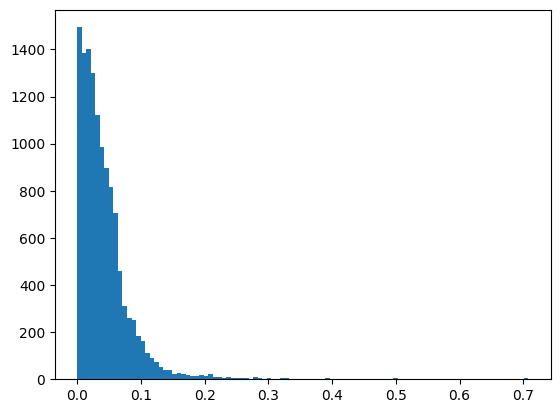

In [3]:
scores_dif = np.abs(buf_fp32_scores - buf_uint8_scores).flatten()
plt.hist(scores_dif, bins=100);
scores_dif.mean(), scores_dif.std(), np.median(scores_dif), scores_dif.max()

Coord dif mean: [6.7134614 6.356434  9.193762  9.298481  4.8645167 4.6503086]
Coord dif std: [4.586167  4.695463  6.904789  6.811266  3.0920346 3.0805058]
Coord dif median: [6.216652  5.7692604 7.566437  7.95475   4.569927  4.2926636]
Coord dif max: [17.602951 18.020782 31.302063 30.81076  14.012733 14.437912]


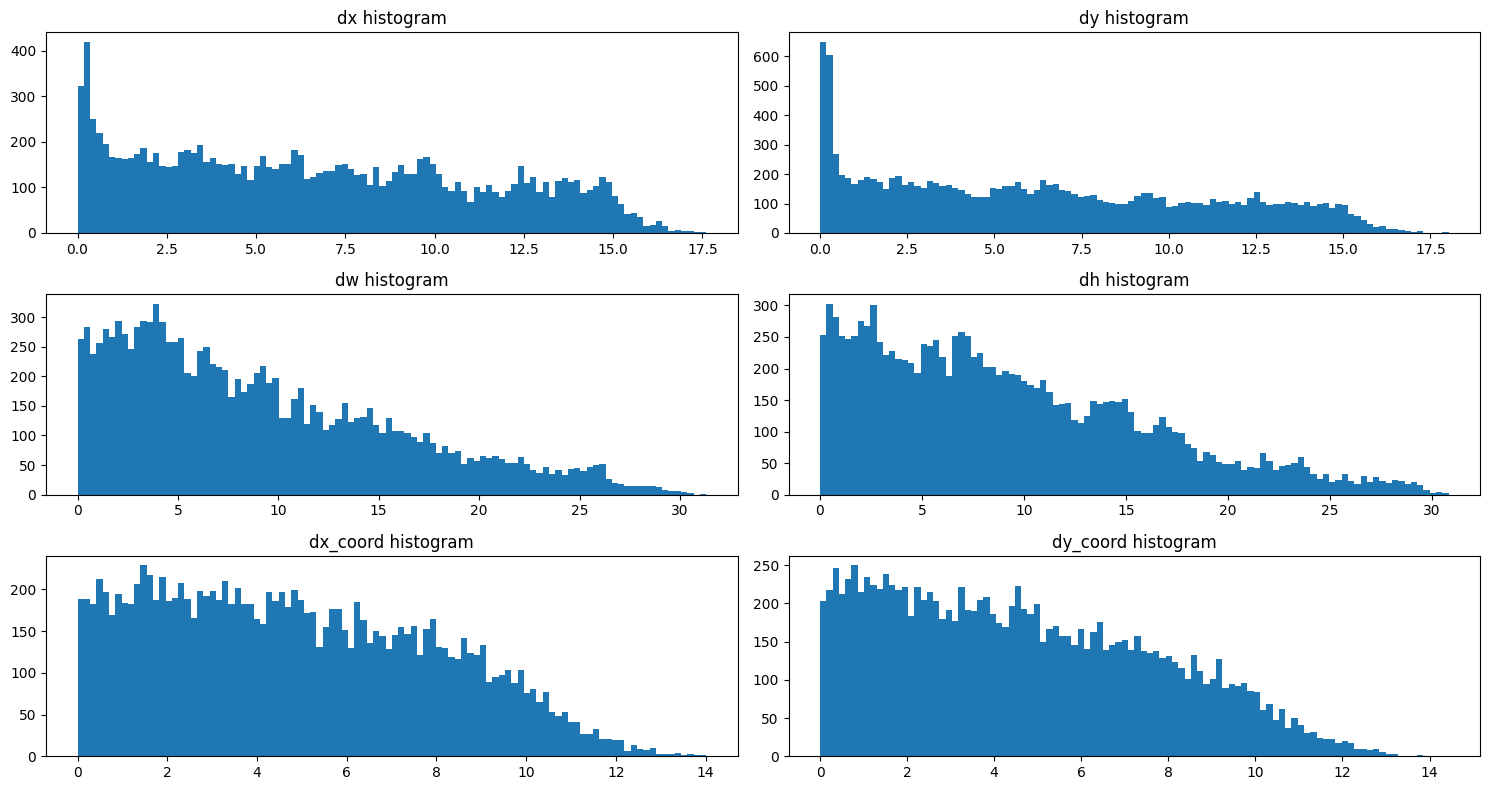

In [4]:
coord_dif = np.abs(buf_fp32_boxes - buf_uint8_boxes)
print("Coord dif mean:", coord_dif.mean(axis=0))
print("Coord dif std:", coord_dif.std(axis=0))
print("Coord dif median:", np.median(coord_dif, axis=0))
print("Coord dif max:", coord_dif.max(axis=0))

plt.figure(figsize=(15, 8))
plt.subplot(3, 2, 1)
plt.hist(coord_dif[:, 0].flatten(), bins=100)
plt.title('dx histogram')
plt.subplot(3, 2, 2)
plt.hist(coord_dif[:, 1].flatten(), bins=100)
plt.title('dy histogram')
plt.subplot(3, 2, 3)
plt.hist(coord_dif[:, 2].flatten(), bins=100)
plt.title('dw histogram')
plt.subplot(3, 2, 4)
plt.hist(coord_dif[:, 3].flatten(), bins=100)
plt.title('dh histogram')
plt.subplot(3, 2, 5)
plt.hist(coord_dif[:, 4].flatten(), bins=100)
plt.title('dx_coord histogram')
plt.subplot(3, 2, 6)
plt.hist(coord_dif[:, 5].flatten(), bins=100)
plt.title('dy_coord histogram')

plt.tight_layout()


In [6]:
# Train linear regression models for all 6 box coordinates
coord_names = ['dx', 'dy', 'dw', 'dh', 'dx_coord', 'dy_coord']
models = []

params = {}

# First: Train models on full dataset
for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    # model = LinearRegression(fit_intercept=True)
    model = RidgeCV(fit_intercept=True, alphas=np.logspace(-2, 1, 50))
    model.fit(X, y)
    models.append(model)

    print(f"{coord_names[i]}:")
    print(f"  Coef: {model.coef_[0]:.6f}, Intercept: {model.intercept_:.6f}, Alpha: {model.alpha_ if hasattr(model, 'alpha_') else 'N/A'}")
    params[coord_names[i]] = {
        'coef': float(model.coef_[0]),
        'intercept': float(model.intercept_),
        'alpha': float(model.alpha_) if hasattr(model, 'alpha_') else None
    }

print("\n" + "="*50)
print("Model training completed\n")

# MSE comparison: FP32 vs UINT8 (without regression)
print("\n" + "="*50)
print("MSE: FP32 vs UINT8 (direct conversion)\n")
mse_uint8 = mean_squared_error(buf_fp32_boxes, buf_uint8_boxes, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_uint8[i]:.4f}")
print(f"Overall MSE: {mse_uint8.mean():.4f}")

# MSE comparison: FP32 vs Regression predictions (UINT8 as input)
print("\n" + "="*50)
print("MSE: FP32 vs Regression predictions (UINT8 input)\n")
predictions = np.column_stack([models[i].predict(buf_uint8_boxes[:, i].reshape(-1, 1)) for i in range(6)])
mse_regression = mean_squared_error(buf_fp32_boxes, predictions, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_regression[i]:.4f}")
print(f"Overall MSE: {mse_regression.mean():.4f}")

# Improvement comparison
print("\n" + "="*50)
print("MSE Improvement (UINT8 -> Regression)\n")
for i, name in enumerate(coord_names):
    improvement = ((mse_uint8[i] - mse_regression[i]) / mse_uint8[i]) * 100
    print(f"{name}: {improvement:.2f}%")
print(f"Overall: {((mse_uint8.mean() - mse_regression.mean()) / mse_uint8.mean()) * 100:.2f}%")

file_name = 'ridge_regression_params_tiny.json'
with open(file_name, 'w') as f:
    json.dump(params, f, indent=4)
print(f"\nRegression parameters saved to '{file_name}'")

dx:
  Coef: 0.981207, Intercept: 1.876063, Alpha: 10.0
dy:
  Coef: 0.980490, Intercept: 1.071448, Alpha: 10.0
dw:
  Coef: 0.651353, Intercept: 21.623704, Alpha: 10.0
dh:
  Coef: 0.600998, Intercept: 22.150348, Alpha: 10.0
dx_coord:
  Coef: 1.001219, Intercept: 0.185061, Alpha: 10.0
dy_coord:
  Coef: 0.995671, Intercept: 0.669470, Alpha: 10.0

Model training completed


MSE: FP32 vs UINT8 (direct conversion)

dx: 66.1033
dy: 62.4515
dw: 132.2017
dh: 132.8553
dx_coord: 33.2241
dy_coord: 31.1149
Overall MSE: 76.3251

MSE: FP32 vs Regression predictions (UINT8 input)

dx: 63.3963
dy: 60.2769
dw: 86.0604
dh: 79.1339
dx_coord: 33.0636
dy_coord: 31.0470
Overall MSE: 58.8297

MSE Improvement (UINT8 -> Regression)

dx: 4.10%
dy: 3.48%
dw: 34.90%
dh: 40.44%
dx_coord: 0.48%
dy_coord: 0.22%
Overall: 22.92%

Regression parameters saved to 'ridge_regression_params_tiny.json'
